In [1]:
import os, sys
os.chdir("..")                 # subir a la raíz del proyecto (para que encuentre data/)
sys.path.append("src")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from state import obtener_mensajes, construir_estado, estado_a_dataframes
from transform import unir_anios, MAPEO, COLUMNAS_COMUNES

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

cargo el estado se usa la copia local, sin volver a Kafka

In [2]:
mensajes = obtener_mensajes()
estado, duplicados = construir_estado(mensajes)
dfs = estado_a_dataframes(estado)

for anio, df in dfs.items():
    print(anio, df.shape)
dfs[2015].head()

Cargando mensajes desde la copia local: data\raw_messages.json
2015 (158, 15)
2016 (157, 16)
2017 (155, 15)
2018 (156, 12)
2019 (156, 12)


,Country,Region,Happiness Rank,Happiness Score,Standard Error,Economy (GDP per Capita),Family,Health (Life Expectancy),Freedom,Trust (Government Corruption),Generosity,Dystopia Residual,year,source_file,record_id
0,Denmark,Western Europe,3,7.527,0.03328,1.32548,1.36058,0.87464,0.64938,0.48357,0.34139,2.49204,2015,2015.csv,2015-3
1,Canada,North America,5,7.427,0.03553,1.32629,1.32261,0.90563,0.63297,0.32957,0.45811,2.45176,2015,2015.csv,2015-5
2,Israel,Middle East and Northern Africa,11,7.278,0.03470,1.22857,1.22393,0.91387,0.41319,0.07785,0.33172,3.08854,2015,2015.csv,2015-11
3,Brazil,Latin America and Caribbean,16,6.983,0.04076,0.98124,1.23287,0.69702,0.49049,0.17521,0.14574,3.26001,2015,2015.csv,2015-16
4,Oman,Middle East and Northern Africa,22,6.853,0.05335,1.36011,1.08182,0.76276,0.63274,0.32524,0.21542,2.47489,2015,2015.csv,2015-22


dejo las columnas que son las mismas en todos los años columnas comunes y únicas

In [3]:
cols_por_anio = {
    a: set(df.columns) - {"year", "source_file", "record_id"} for a, df in dfs.items()
}
comunes_originales = set.intersection(*cols_por_anio.values())
print("Columnas con el MISMO nombre en los 5 años:", comunes_originales)

todas = set.union(*cols_por_anio.values())
tabla = pd.DataFrame(
    {a: [c in cols for c in sorted(todas)] for a, cols in cols_por_anio.items()},
    index=sorted(todas),
)
display(tabla.replace({True: "✔", False: "–"}))

Columnas con el MISMO nombre en los 5 años: {'Generosity'}


,2015,2016,2017,2018,2019
Country,✔,✔,✔,–,–
Country or region,–,–,–,✔,✔
Dystopia Residual,✔,✔,–,–,–
Dystopia.Residual,–,–,✔,–,–
Economy (GDP per Capita),✔,✔,–,–,–
Economy..GDP.per.Capita.,–,–,✔,–,–
Family,✔,✔,✔,–,–
Freedom,✔,✔,✔,–,–
Freedom to make life choices,–,–,–,✔,✔
GDP per capita,–,–,–,✔,✔


armonizo, descarto y unifico

In [4]:
df_all, descartadas = unir_anios(dfs)

print("Dataset unificado:", df_all.shape)
print("\nColumnas descartadas por año (no comunes a los 5 años):")
for anio, cols in descartadas.items():
    print(f"  {anio}: {cols}")

df_all.info()
df_all.head()

Dataset unificado: (782, 10)

Columnas descartadas por año (no comunes a los 5 años):
  2015: ['Region', 'Happiness Rank', 'Standard Error', 'Dystopia Residual']
  2016: ['Region', 'Happiness Rank', 'Lower Confidence Interval', 'Upper Confidence Interval', 'Dystopia Residual']
  2017: ['Happiness.Rank', 'Whisker.high', 'Whisker.low', 'Dystopia.Residual']
  2018: ['Overall rank']
  2019: ['Overall rank']
<class 'pandas.DataFrame'>
RangeIndex: 782 entries, 0 to 781
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   country                782 non-null    str    
 1   happiness_score        782 non-null    float64
 2   gdp_per_capita         782 non-null    float64
 3   social_support         782 non-null    float64
 4   life_expectancy        782 non-null    float64
 5   freedom                782 non-null    float64
 6   generosity             782 non-null    float64
 7   corruption_perception  781

,country,happiness_score,gdp_per_capita,social_support,life_expectancy,freedom,generosity,corruption_perception,year,record_id
0,Denmark,7.527,1.32548,1.36058,0.87464,0.64938,0.34139,0.48357,2015,2015-3
1,Canada,7.427,1.32629,1.32261,0.90563,0.63297,0.45811,0.32957,2015,2015-5
2,Israel,7.278,1.22857,1.22393,0.91387,0.41319,0.33172,0.07785,2015,2015-11
3,Brazil,6.983,0.98124,1.23287,0.69702,0.49049,0.14574,0.17521,2015,2015-16
4,Oman,6.853,1.36011,1.08182,0.76276,0.63274,0.21542,0.32524,2015,2015-22


doy calidad a los datos limpieza de nulos, duplicados y rangos

In [5]:
print("Nulos por columna:")
print(df_all.isnull().sum())

print("\nFilas con nulos:")
display(df_all[df_all.isnull().any(axis=1)])

print("\nDuplicados exactos:", df_all.duplicated().sum())
print("Países repetidos dentro de un mismo año:",
      df_all.duplicated(subset=["country", "year"]).sum())

print("\nEstadísticas descriptivas por año (happiness_score):")
display(df_all.groupby("year")["happiness_score"].describe())

display(df_all.drop(columns=["country", "record_id"]).describe().T)
print("Nulos por columna:")
print(df_all.isnull().sum())

print("\nFilas con nulos:")
display(df_all[df_all.isnull().any(axis=1)])

print("\nDuplicados exactos:", df_all.duplicated().sum())
print("Países repetidos dentro de un mismo año:",
      df_all.duplicated(subset=["country", "year"]).sum())

print("\nEstadísticas descriptivas por año (happiness_score):")
display(df_all.groupby("year")["happiness_score"].describe())

display(df_all.drop(columns=["country", "record_id"]).describe().T)

Nulos por columna:
country                  0
happiness_score          0
gdp_per_capita           0
social_support           0
life_expectancy          0
freedom                  0
generosity               0
corruption_perception    1
year                     0
record_id                0
dtype: int64

Filas con nulos:


,country,happiness_score,gdp_per_capita,social_support,life_expectancy,freedom,generosity,corruption_perception,year,record_id
525,United Arab Emirates,6.774,2.096,0.776,0.67,0.284,0.186,NaN,2018,2018-20



Duplicados exactos: 0
Países repetidos dentro de un mismo año: 0

Estadísticas descriptivas por año (happiness_score):


,count,mean,std,min,25%,50%,75%,max
year,,,,,,,,
2015,158.0,5.375734,1.145010,2.839,4.52600,5.2325,6.24375,7.587
2016,157.0,5.382185,1.141674,2.905,4.40400,5.3140,6.26900,7.526
2017,155.0,5.354019,1.131230,2.693,4.50550,5.2790,6.10150,7.537
2018,156.0,5.375917,1.119506,2.905,4.45375,5.3780,6.16850,7.632
2019,156.0,5.407096,1.113120,2.853,4.54450,5.3795,6.18450,7.769


,count,mean,std,min,25%,50%,75%,max
happiness_score,782.0,5.379018,1.127456,2.693,4.509750,5.322000,6.189500,7.769000
gdp_per_capita,782.0,0.916047,0.407340,0.000,0.606500,0.982205,1.236187,2.096000
social_support,782.0,1.078392,0.329548,0.000,0.869363,1.124735,1.327250,1.644000
life_expectancy,782.0,0.612416,0.248309,0.000,0.440183,0.647310,0.808000,1.141000
freedom,782.0,0.411091,0.152880,0.000,0.309768,0.431000,0.531000,0.724000
generosity,782.0,0.218576,0.122321,0.000,0.130000,0.201982,0.278832,0.838075
corruption_perception,781.0,0.125436,0.105816,0.000,0.054000,0.091000,0.156030,0.551910
year,782.0,2016.993606,1.417364,2015.000,2016.000000,2017.000000,2018.000000,2019.000000


Nulos por columna:
country                  0
happiness_score          0
gdp_per_capita           0
social_support           0
life_expectancy          0
freedom                  0
generosity               0
corruption_perception    1
year                     0
record_id                0
dtype: int64

Filas con nulos:


,country,happiness_score,gdp_per_capita,social_support,life_expectancy,freedom,generosity,corruption_perception,year,record_id
525,United Arab Emirates,6.774,2.096,0.776,0.67,0.284,0.186,NaN,2018,2018-20



Duplicados exactos: 0
Países repetidos dentro de un mismo año: 0

Estadísticas descriptivas por año (happiness_score):


,count,mean,std,min,25%,50%,75%,max
year,,,,,,,,
2015,158.0,5.375734,1.145010,2.839,4.52600,5.2325,6.24375,7.587
2016,157.0,5.382185,1.141674,2.905,4.40400,5.3140,6.26900,7.526
2017,155.0,5.354019,1.131230,2.693,4.50550,5.2790,6.10150,7.537
2018,156.0,5.375917,1.119506,2.905,4.45375,5.3780,6.16850,7.632
2019,156.0,5.407096,1.113120,2.853,4.54450,5.3795,6.18450,7.769


,count,mean,std,min,25%,50%,75%,max
happiness_score,782.0,5.379018,1.127456,2.693,4.509750,5.322000,6.189500,7.769000
gdp_per_capita,782.0,0.916047,0.407340,0.000,0.606500,0.982205,1.236187,2.096000
social_support,782.0,1.078392,0.329548,0.000,0.869363,1.124735,1.327250,1.644000
life_expectancy,782.0,0.612416,0.248309,0.000,0.440183,0.647310,0.808000,1.141000
freedom,782.0,0.411091,0.152880,0.000,0.309768,0.431000,0.531000,0.724000
generosity,782.0,0.218576,0.122321,0.000,0.130000,0.201982,0.278832,0.838075
corruption_perception,781.0,0.125436,0.105816,0.000,0.054000,0.091000,0.156030,0.551910
year,782.0,2016.993606,1.417364,2015.000,2016.000000,2017.000000,2018.000000,2019.000000


limpieza y exploración de datos, deteccion de Outliers utilizando el método del Rango Intercuartílico. 

Los nombres de columnas difieren entre años y se armonizaron a un esquema común, se detectaron 6 países con nombre inconsistente entre años, que se unificaron, hay 1 valor nulo UAE 2018, corruption_perception que se imputa con la mediana dentro del Pipeline tener en cuenta corruption_perception presenta 67 outliers por IQR, producto de una distribución asimétrica, se conservan por ser valores reales y no hay duplicados.

,variable,outliers_IQR,límite_inf,límite_sup
0,happiness_score,0,1.990,8.709
1,gdp_per_capita,0,-0.338,2.181
2,social_support,10,0.183,2.014
3,life_expectancy,0,-0.112,1.360
4,freedom,0,-0.022,0.863
5,generosity,17,-0.093,0.502
6,corruption_perception,67,-0.099,0.309


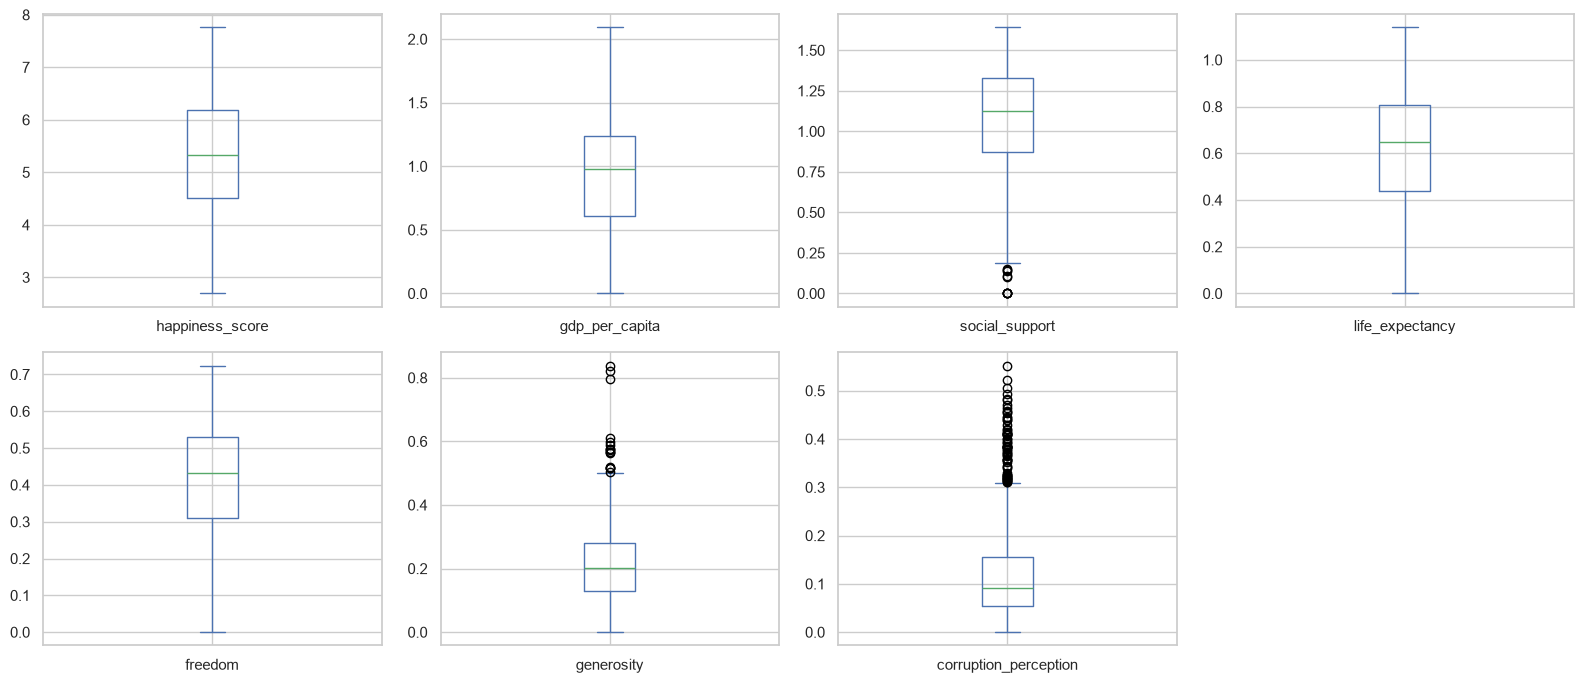

Países en los 5 años: 146 | países en solo algunos: 18


,2015,2016,2017,2018,2019
Angola,✔,✔,✔,✔,–
Belize,–,✔,✔,✔,–
Central African Republic,✔,–,✔,✔,✔
Comoros,✔,✔,–,–,✔
Djibouti,✔,–,–,–,–
Gambia,–,–,–,–,✔
Laos,✔,✔,–,✔,✔
Lesotho,✔,–,✔,✔,✔
Mozambique,✔,–,✔,✔,✔
Namibia,–,✔,✔,✔,✔


In [6]:
# Outliers por variable
numericas = [c for c in COLUMNAS_COMUNES if c != "country"]
resumen = []
for col in numericas:
    q1, q3 = df_all[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = ((df_all[col] < low) | (df_all[col] > high)).sum()
    resumen.append({"variable": col, "outliers_IQR": n, "límite_inf": round(low, 3), "límite_sup": round(high, 3)})
display(pd.DataFrame(resumen))

df_all[numericas].plot(kind="box", subplots=True, layout=(2, 4), figsize=(16, 7), sharey=False)
plt.tight_layout()
plt.show()

# Países que no aparecen en los 5 años (posibles nombres inconsistentes)
paises_por_anio = {a: set(g["country"]) for a, g in df_all.groupby("year")}
en_todos = set.intersection(*paises_por_anio.values())
en_alguno = set.union(*paises_por_anio.values())
parciales = sorted(en_alguno - en_todos)

presencia = pd.DataFrame(
    {a: [p in s for p in parciales] for a, s in paises_por_anio.items()}, index=parciales
)
print(f"Países en los 5 años: {len(en_todos)} | países en solo algunos: {len(parciales)}")
display(presencia.replace({True: "✔", False: "–"}))

usar variables de todos los años: GDP, apoyo social, esperanza de vida, libertad, generosidad, percepción de corrupción, más el país

In [8]:
cols_cero = ["gdp_per_capita", "social_support", "life_expectancy", "freedom", "generosity", "corruption_perception"]

ceros = (df_all[cols_cero] == 0).sum()
print("Cantidad de ceros por variable:")
print(ceros)

mask = (df_all[cols_cero] == 0).any(axis=1)
display(df_all.loc[mask, ["country", "year"] + cols_cero].sort_values(["country", "year"]))

Cantidad de ceros por variable:
gdp_per_capita           5
social_support           5
life_expectancy          5
freedom                  5
generosity               5
corruption_perception    6
dtype: int64


,country,year,gdp_per_capita,social_support,life_expectancy,freedom,generosity,corruption_perception
780,Afghanistan,2019,0.350000,0.517000,0.361000,0.000000,0.158000,0.025000
461,Angola,2017,0.858428,1.104412,0.049869,0.000000,0.097926,0.069720
514,Angola,2018,0.730000,1.125000,0.269000,0.000000,0.079000,0.061000
288,Bosnia and Herzegovina,2016,0.933830,0.643670,0.707660,0.095110,0.298890,0.000000
387,Bosnia and Herzegovina,2017,0.982409,1.069336,0.705186,0.204403,0.328867,0.000000
597,Bosnia and Herzegovina,2018,0.915000,1.078000,0.758000,0.280000,0.216000,0.000000
153,Central African Republic,2015,0.078500,0.000000,0.066990,0.488790,0.238350,0.082890
411,Central African Republic,2017,0.000000,0.000000,0.018773,0.270842,0.280876,0.056565
625,Central African Republic,2018,0.024000,0.000000,0.010000,0.305000,0.218000,0.038000
723,Central African Republic,2019,0.026000,0.000000,0.105000,0.225000,0.235000,0.035000
